# Week 13 — The Forge

Build a small NumPy autograd framework and use it to train three networks on the same four examples. The target is the second input bit. Run this notebook from the `week13` folder.

## Part 1 — The Autograd Tensor

`Tensor` wraps a NumPy array and records the operation and its inputs when autograd is enabled. A tensor with several uses accumulates all of their gradient contributions before propagating back to its own creators. This matters when an intermediate value fans out to multiple branches of the graph.

`tensor.py` contains the graph bookkeeping and the operation implementations for Parts 1, 2, and 5.

In [1]:
import numpy as np

class Tensor:
    def __init__(self, data, autograd=False, creators=None, creation_op=None, id=None):
        self.data = np.array(data)
        self.creators = creators
        self.creation_op = creation_op
        self.grad = None
        self.autograd = autograd

        if id:
            self.id = id
        else:
            self.id = np.random.randint(0,100000)

        self.children = {}
        if creators is not None:
            for c in creators:
                if self.id not in c.children:
                    c.children[self.id] = 1
                else:
                    c.children[self.id] += 1

    def __repr__(self):
        return str(self.data)

    def __str__(self):
        return str(self.data)

    def all_children_accounted_for(self):
        for id in self.children:
            if self.children[id] != 0:
                return False
        return True

    def backward(self, grad = None, grad_origin = None):
        # If self.autograd is false, return a plain tensor takes no part in the walk
        if not self.autograd:
            return

        # If grad is None, start from ones
        if grad is None:
            grad = Tensor(np.ones_like(self.data))

        # If grad_origin is given, a child is reporting. 
        # If that child’s counter is already zero, raise Exception("cannot backprop more than once"); 
        # otherwise decrement it
        if grad_origin:
            if self.children[grad_origin.id] == 0:
                raise Exception("cannot backprop more than once")
            else:
                self.children[grad_origin.id] -= 1

        # Accumulate into self.grad with += rather than overwriting.
        if self.grad is None:
            self.grad = grad
        elif self.grad:
            self.grad += grad

        # Only recurse into creators once all_children_accounted_for() is true, or grad_origin is None
        if self.all_children_accounted_for() or grad_origin is None:
            if self.creation_op is None:
                return
            elif self.creation_op == "add":
                self.creators[0].backward(grad = self.grad, grad_origin = self)
                self.creators[1].backward(grad = self.grad, grad_origin = self)
            elif self.creation_op == "neg":
                self.creators[0].backward(-self.grad, self)
            elif self.creation_op == "sub":
                self.creators[0].backward(self.grad, self)
                self.creators[1].backward(self.grad, self)
            elif self.creation_op == "mul":
                self.creators[0].backward(self.grad * self.creators[1], self)
                self.creators[1].backward(self.grad * self.creators[0], self)
            elif self.creation_op == "mm":
                c0, c1 = self.creators
                c0.backward(Tensor(self.grad.data.dot(c1.data.T)), self)
                c1.backward(Tensor(c0.data.T.dot(self.grad.data)), self)
            elif self.creation_op == "transpose":
                self.creators[0].backward(self.grad.T, self)
            elif "sum" in self.creation_op:
                dim = int(self.creation_op.split("_")[1])
                ds = self.creators[0].data.shape[dim]
                self.creators[0].backward(self.grad.expand(dim, ds), self)
            elif "expand" in self.creation_op:
                dim = int(self.creation_op.split("_")[1])
                self.creators[0].backward(self.grad.sum(dim), self)
            elif self.creation_op == "tanh":
                ones = Tensor(np.ones_like(self.grad.data))
                self.creators[0].backward(grad = self.grad * (ones - self*self), grad_origin = self)
            elif self.creation_op == "sigmoid":
                ones = Tensor(np.ones_like(self.grad.data))
                self.creators[0].backward(grad = self.grad * self * (ones - self), grad_origin = self)

    def __add__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data + other.data, autograd = True, creators = [self, other], creation_op = "add")
        else:
            return Tensor(self.data + other.data)

    def __sub__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data - other.data, autograd = True, creators = [self, other], creation_op = "sub")
        else:
            return Tensor(self.data - other.data)

    def __mul__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data * other.data, autograd = True, creators = [self, other], creation_op = "mul")
        else:
            return Tensor(self.data * other.data)

    def __neg__(self):
        if self.autograd:
            return Tensor(self.data * -1, autograd = True, creators = [self], creation_op = "neg")
        else:
            return Tensor(self.data * -1)

    def __matmul__(self, other):
        if self.autograd and other.autograd:
            return Tensor(self.data.dot(other.data), autograd = True, creators = [self, other], creation_op = "mm")
        else:
            return Tensor(self.data.dot(other.data))

    @property
    def T(self):
        return self.transpose()

    def mm(self, other):
        return self @ other
    
    def transpose(self):
        if self.autograd:
            return Tensor(self.data.T, autograd = True, creators = [self], creation_op = "transpose")
        else:
            return Tensor(self.data.T)

    def sum(self, dim):
        if self.autograd:
            return Tensor(np.sum(self.data, dim), autograd = True, creators = [self], creation_op = f"sum_{dim}")
        else:
            return Tensor(np.sum(self.data, dim))

    def expand(self, dim, n):
        trans_cmd = list(range(0, len(self.data.shape)))
        trans_cmd.insert(dim, len(self.data.shape))
        new_data = self.data.repeat(n).reshape(list(self.data.shape) + [n]).transpose(trans_cmd)
        
        if not self.autograd:
            return Tensor(new_data)
        
        return Tensor(new_data, autograd = True, creators = [self], creation_op = f"expand_{dim}")


    def tanh(self):
        if self.autograd:
            return Tensor(np.tanh(self.data), autograd = True, creators = [self], creation_op = "tanh")
        else:
            return Tensor(np.tanh(self.data))

    def sigmoid(self):
        if self.autograd:
            return Tensor(1 / (1 + np.exp(-self.data)), autograd = True, creators = [self], creation_op = "sigmoid")
        else:
            return Tensor(1 / (1 + np.exp(-self.data)))

## Part 2 — The Operation Table

The forward methods and their backward branches live together in `tensor.py` above. Matrix multiplication uses the saved inputs to compute `grad @ B.T` for `A` and `A.T @ grad` for `B`. Reduction and expansion reverse each other. The backward pass for `sum` expands the gradient across the reduced axis, and the backward pass for `expand` sums across the repeated axis.

## Part 3 — The Optimizer and the Layers

`optim.py` moves each parameter against its gradient and clears the gradient for the next iteration.

In [2]:
class SGD:
    def __init__(self, parameters, alpha):
        self.parameters = parameters
        self.alpha = alpha

    def step(self, zero=True):
        for p in self.parameters:
            p.data -= p.grad.data * self.alpha
            if zero:
                p.grad.data *= 0


In `layers.py`, each `Linear` layer owns a weight matrix and a bias expanded across the batch. `Sequential` passes the result of each layer to the next and gathers their parameters for SGD. The file also includes the activation and loss layers used in Part 5.

In [3]:
import numpy as np
from tensor import Tensor


class Layer:
    def __init__(self):
        self.parameters = []

    def get_parameters(self):
        return self.parameters


class Linear(Layer):
    def __init__(self, n_in, n_out):
        super().__init__()
        W = np.random.randn(n_in, n_out) * np.sqrt(2.0 / n_in)
        self.weight = Tensor(W, autograd=True)
        self.bias   = Tensor(np.zeros(n_out), autograd=True)
        self.parameters.append(self.weight)
        self.parameters.append(self.bias)

    def forward(self, input):
        return input.mm(self.weight) + self.bias.expand(0, len(input.data))


class Sequential(Layer):
    def __init__(self, layers):
        super().__init__()
        self.layers = layers

    def forward(self, input):
        for layer in self.layers:
            input = layer.forward(input)
        return input

    def get_parameters(self):
        parameters = []
        for layer in self.layers:
            parameters.extend(layer.get_parameters())
        return parameters


class Tanh(Layer):
    def __init__(self):
        super().__init__()
    
    def forward(self, input):
        return input.tanh()

class Sigmoid(Layer):
    def __init__(self):
        super().__init__()

    def forward(self, input):
        return input.sigmoid()

class MSELoss(Layer):
    def __init__(self):
        super().__init__()

    def forward(self, pred, target):
        return ((pred-target)*(pred-target)).sum(0)



## Part 4 — Train the MLP

`train_mlp.py` trains the two-layer Sequential MLP with SGD at `alpha=0.01`, then trains the bare MLP with two weight tensors and an update rate of `0.1`. Each run prints ten losses. The script seeds NumPy before the Sequential run and continues from the same random stream for the bare run, so the bare curve uses a different initialization from the handout's separately seeded example.

In [4]:
# Keep the training scripts' printed losses for the plots and echo their output.
import builtins

training_losses = []

def print(*values, **options):
    if len(values) == 1 and isinstance(values[0], Tensor):
        training_losses.append(values[0].data.item())
    builtins.print(*values, **options)

In [5]:
import numpy as np
from tensor import Tensor
from layers import Linear, Sequential
from optim import SGD

# setup
np.random.seed(0)
data = Tensor([[0,0],[0,1],[1,0],[1,1]], autograd=True)
target = Tensor([[0],[1],[0],[1]], autograd=True)

# Using the model
print("-- Training the MLP --")
model = Sequential([Linear(2,3), Linear(3,1)])
optim = SGD(parameters=model.get_parameters(), alpha=0.01)
for i in range(10):
    pred = model.forward(data)
    loss = ((pred - target) * (pred - target)).sum(0)
    loss.backward()
    optim.step()
    print(loss)

# Using the bare engine
print("\n-- Training the Bare Engine --")
w = [Tensor(np.random.rand(2,3), autograd=True),
     Tensor(np.random.rand(3,1), autograd=True)]
for i in range(10):
    pred = data.mm(w[0]).mm(w[1])
    loss = ((pred - target) * (pred - target)).sum(0)
    loss.backward()
    for w_ in w:
        w_.data -= w_.grad.data * 0.1
        w_.grad.data *= 0
    print(loss)


-- Training the MLP --
[2.33428272]
[1.50922784]
[0.98448854]
[0.6478277]
[0.43169175]
[0.29332533]
[0.20503331]
[0.14877319]
[0.11283963]
[0.08970536]

-- Training the Bare Engine --
[2.50232148]
[0.83523948]
[0.17161946]
[0.05177635]
[0.02959586]
[0.01679485]
[0.0092965]
[0.00504177]
[0.00269023]
[0.00141755]


## Part 5 — Add the Bend

`train_deep.py` places a `Tanh` between the linear layers and a `Sigmoid` on the output. The activations let the model represent a nonlinear function. The loss layer sums squared errors over the four inputs, and the tensor graph supplies the gradients for SGD at `alpha=1`.

In [6]:
import numpy as np
from tensor import Tensor
from layers import Linear, Sequential, Tanh, Sigmoid, MSELoss
from optim import SGD

np.random.seed(0)
data = Tensor([[0,0],[0,1],[1,0],[1,1]], autograd=True) # after the seed,
target = Tensor([[0],[1],[0],[1]], autograd=True) # before the model
model = Sequential([Linear(2,3), Tanh(), Linear(3,1), Sigmoid()])
criterion = MSELoss()
optim = SGD(parameters=model.get_parameters(), alpha=1)
for i in range(10):
    pred = model.forward(data)
    loss = criterion.forward(pred, target)
    loss.backward()
    optim.step()
    print(loss)


[1.06372865]
[0.75148144]
[0.57384259]
[0.39574294]
[0.2482279]
[0.15515294]
[0.10423398]
[0.07571169]
[0.05837623]
[0.04700013]


### Training loss

Each point is the loss printed for that iteration, computed before the optimizer update.

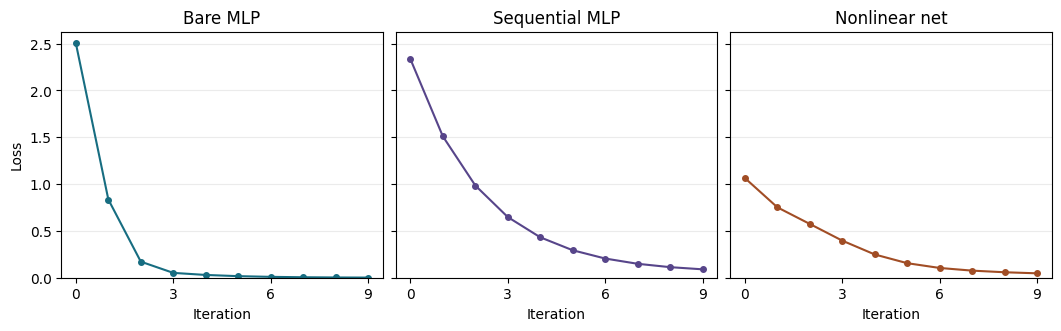

In [7]:
del print

import matplotlib.pyplot as plt

sequential_losses, bare_losses, nonlinear_losses = np.asarray(training_losses).reshape(3, 10)
iterations = np.arange(10)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True, layout="constrained")

for axis, (name, losses, color) in zip(axes, [
    ("Bare MLP", bare_losses, "#176d81"),
    ("Sequential MLP", sequential_losses, "#57458a"),
    ("Nonlinear net", nonlinear_losses, "#a14d25"),
]):
    axis.plot(iterations, losses, color=color, marker="o", markersize=4)
    axis.set_title(name)
    axis.set_xlabel("Iteration")
    axis.set_xticks([0, 3, 6, 9])
    axis.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Loss")
axes[0].set_ylim(bottom=0)
plt.show()

### Run summary

| Run | Final recorded loss (iteration 9) |
| --- | ---: |
| Bare MLP | 0.00141755 |
| Sequential MLP | 0.08970536 |
| Nonlinear net | 0.04700013 |

All three losses decreased at every recorded step.

## Part 6 — Tests, Including a Gradient Check

## Part 7 — Reading the Holocron

### Holocron — Reading

If we deleted the `mm` branch from `Tensor.backward`, the nonlinear network could still compute all four predictions and print a plausible loss. Each matrix multiplication would still produce its usual result and record its two inputs. The trouble would start when backpropagation reached the multiplication in the second `Linear` layer. The result of that multiplication would receive a gradient, but the layer's weight matrix and the activation feeding it would receive none. The first layer's weights and bias would also miss their gradients because the only path back to them runs through that activation. The second layer's bias could still receive a gradient through the addition and expansion. In this implementation, SGD would raise an error when it tried to read `p.grad.data` for a parameter whose gradient was still `None`.

Vex kept the stroke that gave the technique its power and cut the stroke that made its effects answerable. The same omission lets a model make predictions while cutting off the feedback some parameters need to learn. A whole-network gradient check would catch it before merge. I would perturb one weight in the second linear layer in both directions and use the two resulting losses to estimate its gradient. Backpropagation would return no gradient for that weight even though the finite difference measures how it changes the loss.